---
execute: 
  skip: true
---

In [1]:
import awkward as ak
import json
import numpy as np
import pyarrow.compute
from matplotlib import pyplot as plt
import pathlib

In [2]:
data = ak.from_json(pathlib.Path("data", "data.json"))
data

<Array [[...], [...], [...], ..., [...], [...]] type='3083 * var * union[st...'>

In [3]:
time = ak.enforce_type(data[:, 0], "string")
value = ak.enforce_type(data[:, 1], "float64")

Drop the fractional bits

In [4]:
time_no_frac = ak.str.split_pattern(time, ".", max_splits=1)[:, 0]
time_no_frac

<Array ['2026-01-17T13:15:10', ..., '2026-11-03T20:05:03'] type='3083 * string'>

In [5]:
datetime = ak.from_arrow(
    pyarrow.compute.strptime(
        ak.to_arrow(time_no_frac, extensionarray=False),
        "%Y-%m-%dT%H:%M:%S",
        "us",
    )
)

In [6]:
dataset = ak.zip({"datetime": datetime, "value": value})

Group by value, to remove duplicates

In [7]:
steps = ak.run_lengths(value)
by_count = ak.unflatten(dataset, steps)
deduplicated = by_count[:, 0]

In [8]:
deduplicated["value"] = np.arange(len(deduplicated))

Group by month, and count normalised events per month

In [9]:
month = ak.from_arrow(pyarrow.compute.month(ak.to_arrow(deduplicated.datetime, extensionarray=False)))
group = ak.run_lengths(month)
by_month = ak.unflatten(ak.with_field(deduplicated, month, "month"), group)

In [10]:
first = by_month[:, 0, "value"]
last = by_month[:, -1, "value"]

In [11]:
by_month

<Array [[{datetime: ..., ...}, ...], ...] type='11 * var * {datetime: ?date...'>

In [12]:
month_count = (last - first) / ak.count(first - last, axis=-1)

In [13]:
month_count

<Array [11.2, 13, 16, 18.4, ..., 11.1, 8.36, 13.2, 1.18] type='11 * float64'>

In [14]:
months = ak.str.to_categorical(["Jan", "Feb", "Mar", "Apr", "May", "Jun","Jul", "Aug", "Sep", "Oct", "Nov"])

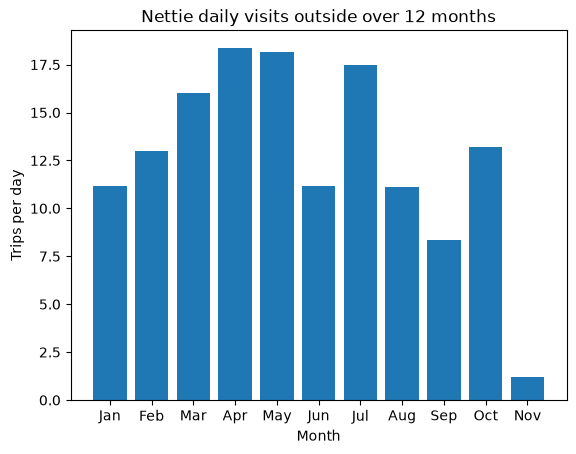

In [15]:
#| label: nettie-visits
m = by_month.month[:, 0]
plt.figure()
plt.title("Nettie daily visits outside over 12 months")
plt.bar(months[m - 1], month_count)
plt.xlabel("Month")
plt.ylabel("Trips per day")

j = np.s_[4:8]
ax = plt.gca()
plt.show()